# Customer-Support Response Generation with a GRU Encoder–Decoder

**Course:** NLP · **Author:** Wifek Chabir

**Task.** Given a customer's message, generate the reply of a customer-support agent.

**Motivation.** Many support requests are repetitive. A model that writes a first reply automatically can reduce response time and agents' workload.

**Problem formulation.** The input x is the customer's message (a sequence of subword tokens). The output y is the agent's reply. The model learns p(y | x) = ∏ p(y_t | y_<t, x): it predicts the next token given the input and the tokens already generated. It is trained with token-level cross-entropy.

**What we build.** Two encoder–decoder models, both written from scratch in PyTorch (no pretrained model, no API):
1. **Baseline:** GRU encoder → GRU decoder.
2. **Baseline + attention:** the same model, with attention added to the decoder.

Everything else (data, tokenizer, hyperparameters, epochs) is identical, so any difference in the results comes from attention alone.

**Pipeline.** text preprocessing → vocabulary → tokenization → embeddings → encoder → decoder → training → generation → evaluation.

**Outline.** 1 Dataset · 2 Preprocessing and split · 3 Tokenizer · 4 Padding and DataLoaders · 5 Encoder · 6 Attention and decoder · 7 Seq2Seq and teacher forcing · 8 Training · 9 Generation · 10 Evaluation · 11 Baseline vs. attention · 12 Examples and error analysis · 13 Discussion and conclusion

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, shutil
SAVE_DIR = "/content/drive/MyDrive/nlp_project"
os.makedirs(SAVE_DIR, exist_ok=True)

Mounted at /content/drive


## 1- Setup and load the data

**Dataset.** [Bitext Customer Support LLM Chatbot Training Dataset](https://huggingface.co/datasets/bitext/Bitext-customer-support-llm-chatbot-training-dataset) from Hugging Face, loaded with the `datasets` library. It contains 26,872 synthetic (customer message → agent reply) pairs.

**Fields.** `instruction` is the customer message (**model input**). `response` is the agent reply (**model target**). `intent` (27 values) is used only to stratify the split. `category` and `flags` are not used.

The next cells load the data, then describe its size and text lengths.

In [2]:
!pip install -q datasets sentencepiece sacrebleu rouge-score

import re
import random
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
cuda


In [ ]:
ds = load_dataset("bitext/Bitext-customer-support-llm-chatbot-training-dataset")
df = ds["train"].to_pandas()
print(df.shape)
df.head()

(26872, 5)


,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...


In [ ]:
print(df.columns.tolist())
print(df["category"].nunique(), "categories,", df["intent"].nunique(), "intents")
df["src_words"] = df["instruction"].str.split().str.len()
df["tgt_words"] = df["response"].str.split().str.len()
print(df[["src_words", "tgt_words"]].describe())
df[["instruction", "response"]].sample(3, random_state=1).values

['flags', 'instruction', 'category', 'intent', 'response']
11 categories, 27 intents
          src_words     tgt_words
count  26872.000000  26872.000000
mean       8.690979    104.789037
std        2.605004     52.966204
min        1.000000      9.000000
25%        7.000000     72.000000
50%        9.000000     90.000000
75%       11.000000    124.000000
max       16.000000    402.000000


array([['how can I check bill  #12588?',
        'I appreciate your inquiry regarding how to check your bill with the number #{{Invoice Number}}. To assist you with this, please follow these steps:\n\n1. Log in to your account on our website.\n2. Navigate to the "Billing" or "Invoices" section.\n3. Look for the option to view your invoices.\n4. Enter the invoice number #{{Invoice Number}} or search for the specific date range if needed.\n5. Click on the invoice to open and review the details.\n\nIf you encounter any difficulties or require further assistance during this process, please don\'t hesitate to let me know. I\'ll be more than happy to help you navigate through it smoothly.'],
       ["I'm rtying to cancel order {{Order Number}}",
        "I'm following the urgency of canceling your order with the order number {{Order Number}}. I apologize for any inconvenience caused. To assist you with the cancellation process, please follow these steps:\n\n1. Log into your {{Online Company 

## 2- Preprocessing and split

**Preprocessing steps and why we need each one.**
1. **Lowercasing:** "Order" and "order" become the same word, so the vocabulary is smaller and each token is seen more often.
2. **Placeholder conversion:** `{{Order Number}}` becomes the single token `<order_number>`. The original has spaces and braces that a tokenizer would split into pieces. As one token, the model can learn to copy it.
3. **Whitespace normalization:** repeated spaces and line breaks become one space. A side effect: numbered step lists in some responses become running text.
4. **Duplicate removal:** pairs with identical input and response are dropped (none were found: 26,872 pairs remain).
5. **Split 80 / 10 / 10**, stratified by `intent` with seed 42, so every intent appears in train, validation and test.

Punctuation is kept, because it is part of natural support replies.

In [15]:
def clean(text):
    text = str(text).strip()
    text = re.sub(r"\{\{(.*?)\}\}",
                  lambda m: "<" + m.group(1).strip().lower().replace(" ", "_") + ">", text)
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    return text

In [ ]:
data = df[["instruction", "response", "intent"]].copy()
data["instruction"] = data["instruction"].map(clean)
data["response"] = data["response"].map(clean)
data = data.drop_duplicates(subset=["instruction", "response"]).reset_index(drop=True)
print(len(data))
data.iloc[0].to_dict()

26872


{'instruction': 'question about cancelling order <order_number>',
 'response': "i've understood you have a question regarding canceling order <order_number>, and i'm here to provide you with the information you need. please go ahead and ask your question, and i'll do my best to assist you.",
 'intent': 'cancel_order'}

In [ ]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(data, test_size=0.2, random_state=SEED, stratify=data["intent"])
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=SEED, stratify=temp_df["intent"])
print(len(train_df), len(val_df), len(test_df))

21497 2687 2688


In [3]:
train_inputs = set(train_df["instruction"])
print("share of test inputs that also appear in train:", test_df["instruction"].isin(train_inputs).mean())

share of test inputs that also appear in train: 0.13467261904761904


**Analysis.** The split gives 21,497 train / 2,687 validation / 2,688 test pairs. The test set is never used for training or model selection. We checked the overlap: **13.5% of test messages also appear word for word in the training set**, always with a different reply, since the dataset contains no duplicate (message, reply) pairs. The other 86.5% are new messages, but many are close variants of training messages (same template with different wording or typos). Because the dataset is templated, the test set is easier than real customer chats, so the scores are likely optimistic.

## 3- Subword tokenizer and special tokens

**Why subwords.** A word-level vocabulary would map rare words, typos and unseen words to `<UNK>`, losing information. **BPE** (byte-pair encoding) builds the vocabulary from frequent character sequences, so a rare word is split into smaller known pieces instead.

**Settings.** One SentencePiece BPE model, shared by input and output, with a vocabulary of 4,000 tokens. It is trained on the **training split only**, so no information from validation or test leaks into the vocabulary.

**Special tokens.**
| Token | Id | Role |
|---|---|---|
| `<PAD>` | 0 | fills short sequences so a batch is rectangular (ignored by the loss) |
| `<UNK>` | 1 | unknown token (almost never needed with subwords) |
| `<SOS>` | 2 | start of the target; first input of the decoder |
| `<EOS>` | 3 | end of the target; tells the decoder when to stop |

The 314 placeholders (e.g. `<order_number>`) are registered as single tokens.

In [3]:
PAD, UNK, SOS, EOS = 0, 1, 2, 3

In [ ]:
import sentencepiece as spm

# placeholders become single tokens
placeholders = sorted(set(re.findall(r"<[a-z0-9_]+>",
                       " ".join(train_df["instruction"]) + " " + " ".join(train_df["response"]))))
print(len(placeholders), placeholders[:10])

with open("train_text.txt", "w") as f:
    for t in pd.concat([train_df["instruction"], train_df["response"]]):
        f.write(t + "\n")

spm.SentencePieceTrainer.train(
    input="train_text.txt", model_prefix="bpe", vocab_size=4000, model_type="bpe",
    pad_id=0, unk_id=1, bos_id=2, eos_id=3,
    pad_piece="<PAD>", unk_piece="<UNK>", bos_piece="<SOS>", eos_piece="<EOS>",
    user_defined_symbols=placeholders)

sp = spm.SentencePieceProcessor(model_file="bpe.model")

VOCAB_SIZE = sp.get_piece_size()
print("Vocab size: ", VOCAB_SIZE)
s = train_df["instruction"].iloc[0]
print(s)
print(sp.encode(s, out_type=str))
print(sp.encode(s))

314 ['<access_key>', '<access_key_recovery>', '<access_key_reset_page_url>', '<access_key_retrieval>', '<account>', '<account_access_key_reset>', '<account_category>', '<account_change>', '<account_closure_process>', '<account_closure_timeframe>']
Vocab size:  4000
i want assistance informing of a trouble with payment
['▁i', '▁want', '▁assistance', '▁informing', '▁of', '▁a', '▁trouble', '▁with', '▁payment']
[325, 731, 489, 2126, 395, 320, 1236, 367, 554]


In [ ]:
shutil.copy("bpe.model", SAVE_DIR)
shutil.copy("bpe.vocab", SAVE_DIR)
train_df.to_csv(f"{SAVE_DIR}/train.csv", index=False)
val_df.to_csv(f"{SAVE_DIR}/val.csv", index=False)
test_df.to_csv(f"{SAVE_DIR}/test.csv", index=False)

**Analysis.**
- The vocabulary has 4,000 tokens, which include the 4 special tokens and the 314 placeholders.
- In the example, a 9-word sentence becomes 9 tokens: common words are single tokens. Rare words are split into pieces.
- Placeholders such as `<order_number>` stay whole, so the model can copy them into its replies.

In [ ]:
src_len = train_df["instruction"].map(lambda t: len(sp.encode(t)))
tgt_len = train_df["response"].map(lambda t: len(sp.encode(t)))
print(src_len.quantile([.5, .95, .99]).tolist())
print(tgt_len.quantile([.5, .95, .99]).tolist())

[9.0, 15.0, 16.0]
[105.0, 244.0, 355.0]


**Analysis.** Customer messages are short: the median is 9 tokens and the 99th percentile is 16, so `MAX_SRC = 24` keeps every input complete. Responses are long: median 105 tokens, 95th percentile 244. We set `MAX_TGT = 256`, which keeps most responses complete without making training too slow.

In [ ]:
MAX_SRC, MAX_TGT = 24, 256

In [ ]:
print("responses that fit completely:", (tgt_len <= MAX_TGT - 2).mean())

responses that fit completely: 0.9561334139647393


**Analysis.** 95.6% of the responses fit completely in 256 tokens. The other 4.4% are truncated, so the model never sees their endings. This is a limitation, reported in the discussion.

In [ ]:
from collections import Counter
cnt = Counter(re.findall(r"<[a-z0-9_]+>", " ".join(train_df["instruction"]) + " " + " ".join(train_df["response"])))
print(cnt.most_common(8)); print("appear < 5 times:", sum(c < 5 for c in cnt.values()))

[('<order_number>', 6425), ('<account_type>', 4310), ('<account_category>', 3091), ('<online_order_interaction>', 2139), ('<customer_support_phone_number>', 2110), ('<website_url>', 2018), ('<customer_support_hours>', 1856), ('<invoice_number>', 1219)]
appear < 5 times: 251


**Analysis.** The most frequent placeholder is `<order_number>` (6,425 uses). But **251 of the 314 placeholders appear fewer than 5 times**. They use about 8% of the 4,000 vocabulary slots and are hard for the model to learn. A smaller placeholder set, or a larger vocabulary, could be tested in future work.

## 4- Dataset, padding, DataLoader

**Numerical representation.** Each text becomes a list of token ids (e.g. `[325, 731, 489, …]`). Inside the model, an embedding layer turns each id into a 128-dimensional vector.

**Targets.** Each target is `<SOS>` + tokens + `<EOS>`.

**Truncation.** Inputs are cut at 24 tokens and targets at 256 (including `<SOS>` and `<EOS>`).

**Padding.** Sequences in a batch are padded with `<PAD>` to the same length. Padding is handled in three places: the loss ignores `<PAD>` positions, the encoder skips them (packed sequences), and attention masks them (they get zero weight).

**DataLoaders.** Batch size 64. Only the training loader shuffles. Validation and test are not shuffled, so generated replies stay aligned with `test_df`.

In [4]:
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

In [26]:
class SupportDataset(Dataset):
    def __init__(self, df):
        self.src = df["instruction"].tolist()
        self.tgt = df["response"].tolist()
    def __len__(self):
        return len(self.src)
    def __getitem__(self, i):
        s = sp.encode(self.src[i])[:MAX_SRC]                      # truncate input
        t = [SOS] + sp.encode(self.tgt[i])[:MAX_TGT - 2] + [EOS]  # add <SOS>/<EOS>
        return torch.tensor(s), torch.tensor(t)

def collate(batch):
    src, tgt = zip(*batch)
    src_lens = torch.tensor([len(s) for s in src])
    src = pad_sequence(src, batch_first=True, padding_value=PAD)
    tgt = pad_sequence(tgt, batch_first=True, padding_value=PAD)
    return src, src_lens, tgt

BATCH = 64
train_dl = DataLoader(SupportDataset(train_df), BATCH, shuffle=True,  collate_fn=collate)
val_dl   = DataLoader(SupportDataset(val_df),   BATCH, shuffle=False, collate_fn=collate)
test_dl  = DataLoader(SupportDataset(test_df),  BATCH, shuffle=False, collate_fn=collate)

src, src_lens, tgt = next(iter(train_dl))
print(src.shape, tgt.shape)

torch.Size([64, 16]) torch.Size([64, 256])


**Analysis.** A batch has 64 pairs. Inputs are padded to the longest message in the batch (here 16 tokens). Targets are padded to 256, because almost every batch contains at least one very long response.

## 5- Encoder

**Role.** The encoder reads the customer's message and builds a representation of it.

**Architecture.**
- Embedding: vocabulary 4,000 → 128 dimensions (the `<PAD>` embedding is fixed at zero).
- GRU: **1 layer, unidirectional**, hidden dimension **256**.
- Dropout 0.2 on the embeddings.

**Output.** The encoder returns two things:
1. the **final hidden state** (1 × batch × 256), which summarizes the whole message. This is the encoder's final representation. Packed sequences make sure it is taken at the last real token, not at padding.
2. the **hidden state at every position** (batch × length × 256), which only the attention model uses.

In [6]:
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

class Encoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hid_dim, dropout=0.2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.gru = nn.GRU(emb_dim, hid_dim, batch_first=True)   # 1 layer, unidirectional
        self.dropout = nn.Dropout(dropout)

    def forward(self, src, src_lens):
        emb = self.dropout(self.embedding(src))                       # (B, S, emb)
        packed = pack_padded_sequence(emb, src_lens.cpu(), batch_first=True, enforce_sorted=False)
        packed_out, hidden = self.gru(packed)                         # skips <PAD> positions
        outputs, _ = pad_packed_sequence(packed_out, batch_first=True, total_length=src.size(1))
        return outputs, hidden       # outputs: (B, S, H)   hidden: (1, B, H) = final summary

## 6- Attention and Decoder

**Decoder.** It generates the reply one token at a time.
- **Input at each step:** the previous token (`<SOS>` at the first step). In the attention model it also receives the context vector.
- **Initial state:** the encoder's final hidden state.
- **Architecture:** Embedding (128) → GRU (256) → Linear (to 4,000 values, one per vocabulary token).
- **Prediction:** a softmax over the 4,000 values gives the probability of each next token.
- **Stopping:** generation ends at `<EOS>` or after 254 tokens.

**Why attention.** Without it, the whole message must fit into one 256-dimensional vector, which is a bottleneck. With attention, the decoder can look back at every input token at every step.

**How attention works (additive attention).**
1. **Scores:** for every input position i, score_i = vᵀ · tanh(W_e · h_i + W_d · s), where h_i is the encoder state at position i and s is the decoder's previous hidden state.
2. **Weights:** a softmax over the scores gives weights that sum to 1. Padding positions are masked so they get zero weight.
3. **Context vector:** the weighted sum of the encoder states, c = Σ weight_i · h_i.
4. **Use:** c is concatenated to the decoder's GRU input and also to the GRU output before the final linear layer.

The baseline decoder is the same class with attention switched off.

In [7]:
class Attention(nn.Module):
    def __init__(self, hid_dim):
        super().__init__()
        self.W_enc = nn.Linear(hid_dim, hid_dim, bias=False)
        self.W_dec = nn.Linear(hid_dim, hid_dim)
        self.v = nn.Linear(hid_dim, 1, bias=False)

    def forward(self, dec_hidden, enc_outputs, mask):
        # dec_hidden: (B, H)   enc_outputs: (B, S, H)   mask: (B, S), True = real token
        energy = torch.tanh(self.W_enc(enc_outputs) + self.W_dec(dec_hidden).unsqueeze(1))
        scores = self.v(energy).squeeze(2)                    # (B, S) one score per input token
        scores = scores.masked_fill(~mask, -1e9)              # ignore <PAD>
        weights = F.softmax(scores, dim=1)                    # scores -> probabilities
        context = torch.bmm(weights.unsqueeze(1), enc_outputs).squeeze(1)   # (B, H)
        return context, weights

In [8]:
class Decoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hid_dim, use_attention, dropout=0.2):
        super().__init__()
        self.use_attention = use_attention
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.attention = Attention(hid_dim) if use_attention else None
        extra = hid_dim if use_attention else 0               # size of the context vector
        self.gru = nn.GRU(emb_dim + extra, hid_dim, batch_first=True)
        self.fc = nn.Linear(hid_dim + extra, vocab_size)      # hidden state -> score per vocab token
        self.dropout = nn.Dropout(dropout)

    def forward(self, token, hidden, enc_outputs, mask):
        # token: (B,) previous token   hidden: (1, B, H)
        emb = self.dropout(self.embedding(token)).unsqueeze(1)          # (B, 1, emb)
        if self.use_attention:
            context, _ = self.attention(hidden[-1], enc_outputs, mask)
            gru_in = torch.cat([emb, context.unsqueeze(1)], dim=2)
        else:
            gru_in = emb
        output, hidden = self.gru(gru_in, hidden)                       # one step
        output = output.squeeze(1)                                      # (B, H)
        if self.use_attention:
            output = torch.cat([output, context], dim=1)
        return self.fc(output), hidden                                  # logits: (B, vocab)

## 7- Seq2Seq with teacher forcing

**Seq2Seq model.** The encoder reads the input. Its final state becomes the decoder's initial state. The decoder then runs one step per target position.

**Teacher forcing.** During training, the decoder's next input is either the **true previous token** (teacher forcing) or **its own previous prediction**.

**Our strategy:** ratio **0.8**. At each time step a random draw decides: with probability 0.8 the true token is fed, otherwise the model's own prediction. One draw per step is shared by all sequences in the batch. Validation uses ratio 1.0, so validation loss is a clean next-token measure.

**Why not always 1.0:** with only teacher forcing, the model never practises on its own mistakes, but at generation time it must. A ratio below 1 exposes it to its own predictions during training.

In [9]:
class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder, self.decoder = encoder, decoder

    def forward(self, src, src_lens, tgt, tf_ratio=0.8):
        mask = src != PAD
        enc_outputs, hidden = self.encoder(src, src_lens)     # hidden = initial decoder state
        token = tgt[:, 0]                                      # <SOS>
        outputs = []
        for t in range(tgt.size(1) - 1):
            logits, hidden = self.decoder(token, hidden, enc_outputs, mask)
            outputs.append(logits)
            use_teacher = random.random() < tf_ratio
            token = tgt[:, t + 1] if use_teacher else logits.argmax(1)
        return torch.stack(outputs, dim=1)                     # (B, T-1, vocab)

In [10]:
EMB_DIM, HID_DIM = 128, 256

def build_model(use_attention):
    enc = Encoder(VOCAB_SIZE, EMB_DIM, HID_DIM)
    dec = Decoder(VOCAB_SIZE, EMB_DIM, HID_DIM, use_attention)
    return Seq2Seq(enc, dec).to(device)

In [ ]:
baseline = build_model(False)
attn_model = build_model(True)
count = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)
print("baseline params:", count(baseline), "| attention params:", count(attn_model))

src, src_lens, tgt = next(iter(train_dl))
out = attn_model(src.to(device), src_lens, tgt.to(device))
print(out.shape)

baseline params: 2644896 | attention params: 3997088
torch.Size([64, 255, 4000])


**Analysis.**
- The baseline has **2,644,896** parameters and the attention model **3,997,088** (+51%).
- The difference is 1,352,192 parameters: 1,024,000 from the output layer (it now takes 512 inputs, hidden state + context, instead of 256), 196,608 from the larger GRU input in the decoder, and 131,584 from the attention layers themselves. About **76% of the extra parameters are in the output layer**, not in attention.
- The output shape (64, 255, 4000) is: batch × decoding steps × vocabulary size, one score per vocabulary token at every step.

## 8- Training

**Training setup.** Both models use exactly the same settings.

| Setting | Value |
|---|---|
| Loss | token-level cross-entropy (ignoring `<PAD>`) |
| Optimizer | Adam |
| Learning rate | 1e-3 |
| Gradient clipping | 1.0 |
| Epochs | 20 |
| Batch size | 64 |
| Embedding dimension | 128 |
| Hidden dimension | 256 |
| Layers | 1 |
| Dropout | 0.2 |
| Teacher-forcing ratio | 0.8 (training), 1.0 (validation) |
| Seed | 42 |

**Monitoring.** Training loss and validation loss are recorded at every epoch. The weights with the lowest validation loss are kept. A checkpoint is saved after every epoch to Google Drive, so training can resume after a disconnect.

In [11]:
import math, time
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

criterion = nn.CrossEntropyLoss(ignore_index=PAD)
EPOCHS = 20
LR = 1e-3
TF_RATIO = 0.8
CLIP = 1.0

def run_epoch(model, loader, optimizer=None, tf_ratio=1.0, desc=""):
    training = optimizer is not None
    model.train(training)
    total_loss, total_tokens = 0.0, 0
    bar = tqdm(loader, desc=desc, leave=False)              # progress bar over batches
    with torch.set_grad_enabled(training):
        for src, src_lens, tgt in bar:
            src, tgt = src.to(device), tgt.to(device)
            out = model(src, src_lens, tgt, tf_ratio)       # (B, T-1, V)
            target = tgt[:, 1:]
            loss = criterion(out.reshape(-1, out.size(-1)), target.reshape(-1))
            if training:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), CLIP)
                optimizer.step()
            n = (target != PAD).sum().item()
            total_loss += loss.item() * n
            total_tokens += n
            bar.set_postfix(loss=f"{total_loss / total_tokens:.3f}")   # running loss
    return total_loss / total_tokens

def fmt(seconds):
    m, s = divmod(int(seconds), 60)
    return f"{m}m{s:02d}s"

def train_model(model, name):
    last_path = f"{SAVE_DIR}/{name}_last.pt"     # state after the latest epoch (for resuming)
    best_path = f"{SAVE_DIR}/{name}_best.pt"     # weights of the best validation epoch
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    history = {"train": [], "val": [], "seconds": 0.0}
    start_epoch, best_val = 1, float("inf")

    if os.path.exists(last_path):                # resume if a checkpoint exists
        ck = torch.load(last_path, map_location=device)
        model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
        history, best_val, start_epoch = ck["history"], ck["best_val"], ck["epoch"] + 1
        print(f"[{name}] resuming from epoch {start_epoch}")

    session_start = time.time()
    for epoch in range(start_epoch, EPOCHS + 1):
        t0 = time.time()
        tr = run_epoch(model, train_dl, optimizer, TF_RATIO, desc=f"[{name}] epoch {epoch}/{EPOCHS} train")
        va = run_epoch(model, val_dl, None, 1.0,            desc=f"[{name}] epoch {epoch}/{EPOCHS} val  ")
        history["train"].append(tr); history["val"].append(va)
        history["seconds"] += time.time() - t0

        saved = ""
        if va < best_val:
            best_val = va
            torch.save(model.state_dict(), best_path)
            saved = " (best, saved)"
        torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                    "history": history, "best_val": best_val, "epoch": epoch}, last_path)

        done = epoch - start_epoch + 1
        remaining = (time.time() - session_start) / done * (EPOCHS - epoch)
        print(f"[{name}] epoch {epoch:2d}/{EPOCHS} | train loss {tr:.3f} | val loss {va:.3f} "
              f"| val ppl {math.exp(va):.1f} | epoch {fmt(time.time()-t0)} "
              f"| total {fmt(history['seconds'])} | ~{fmt(remaining)} left{saved}")

    print(f"[{name}] total training time: {fmt(history['seconds'])}")
    model.load_state_dict(torch.load(best_path, map_location=device))   # best epoch
    with open(f"{SAVE_DIR}/{name}_history.json", "w") as f:
        json.dump(history, f)
    return history

In [ ]:
baseline = build_model(False)
attn_model = build_model(True)
hist_base = train_model(baseline, "baseline")
hist_attn = train_model(attn_model, "attention")

[baseline] epoch 1/20 train:   0%|          | 0/336 [00:00<?, ?it/s]

[baseline] epoch 1/20 val  :   0%|          | 0/42 [00:00<?, ?it/s]

[baseline] epoch  1/20 | train loss 4.125 | val loss 2.530 | val ppl 12.6 | epoch 2m13s | total 2m12s | ~42m08s left (best, saved)


[baseline] epoch 2/20 train:   0%|          | 0/336 [00:00<?, ?it/s]

[baseline] epoch 2/20 val  :   0%|          | 0/42 [00:00<?, ?it/s]

[baseline] epoch  2/20 | train loss 2.586 | val loss 1.870 | val ppl 6.5 | epoch 2m04s | total 4m17s | ~38m40s left (best, saved)


... (110 outputs left out)

[attention] epoch 19/20 | train loss 1.303 | val loss 1.089 | val ppl 3.0 | epoch 4m35s | total 87m23s | ~4m36s left (best, saved)


[attention] epoch 20/20 train:   0%|          | 0/336 [00:00<?, ?it/s]

[attention] epoch 20/20 val  :   0%|          | 0/42 [00:00<?, ?it/s]

[attention] epoch 20/20 | train loss 1.289 | val loss 1.084 | val ppl 3.0 | epoch 4m36s | total 91m59s | ~0m00s left (best, saved)
[attention] total training time: 91m59s


**Analysis.**
- **Baseline:** validation loss falls from 2.530 (epoch 1) to 1.870 (epoch 2), 1.617 (epoch 3) and 1.106 (epoch 20). Final training loss is 1.403. Total time 41m52s (about 2m05s per epoch).
- **Attention:** validation loss ends at 1.084, training loss at 1.289. Total time 91m59s (about 4m35s per epoch).
- Both validation losses were still decreasing slightly at epoch 20 (about 0.005 per epoch). More epochs would give small further gains.
- In both runs the best validation loss is at the last epochs, so the saved best checkpoints are the final models.

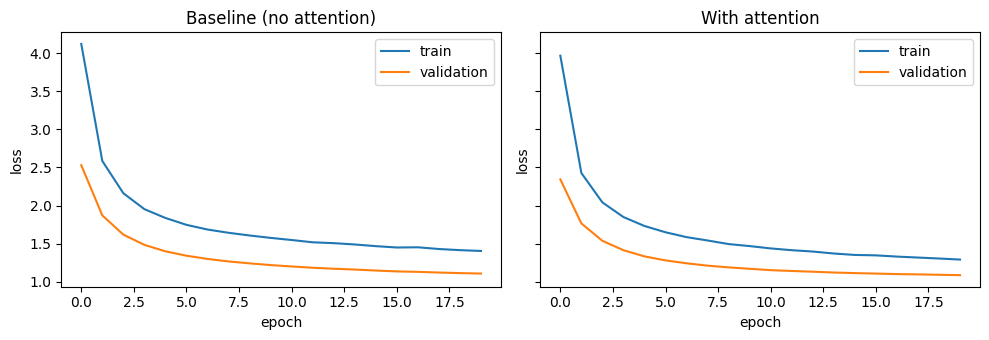

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, h, title in zip(axes, [hist_base, hist_attn], ["Baseline (no attention)", "With attention"]):
    ax.plot(h["train"], label="train"); ax.plot(h["val"], label="validation")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.legend()
plt.tight_layout()
fig.savefig(f"{SAVE_DIR}/learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**Analysis.**
- Both models learn: training and validation losses decrease together.
- The validation loss never goes up, so there is **no overfitting**.
- The training loss stays above the validation loss. This is expected: it is averaged over the whole epoch, measured with dropout on, and uses teacher forcing at 0.8, while validation uses no dropout and ratio 1.0.
- There is no underfitting sign either: losses are low (perplexity about 3) and still slowly improving.
- The attention model has the lower validation loss at the end of training.

## 9- Generation

**Greedy decoding.** After training, the model generates text for inputs it has never seen. There is no target and no teacher forcing:
1. Feed `<SOS>` to the decoder, with the encoder's final state as the initial state.
2. The decoder gives a probability for every token. We take the **most probable token** (greedy decoding).
3. Feed that token back as the next input.
4. Repeat until the model outputs `<EOS>` or 254 tokens have been generated (the stopping criterion).

The same preprocessing (`clean`, tokenizer, truncation) is applied to the input text. The cell below generates replies for three test examples with both models.

In [13]:
@torch.no_grad()
def generate(model, text, max_len=MAX_TGT - 2):
    model.eval()
    ids = sp.encode(clean(text))[:MAX_SRC]                  # same preprocessing as training
    src = torch.tensor([ids], device=device)
    src_lens = torch.tensor([len(ids)])
    mask = src != PAD
    enc_outputs, hidden = model.encoder(src, src_lens)
    token = torch.tensor([SOS], device=device)
    out_ids = []
    for _ in range(max_len):
        logits, hidden = model.decoder(token, hidden, enc_outputs, mask)
        token = logits.argmax(1)                            # greedy: most probable token
        if token.item() == EOS:                             # stopping criterion
            break
        out_ids.append(token.item())
    return sp.decode(out_ids)

In [16]:
for i in range(3):
    row = test_df.iloc[i]
    print("INPUT    :", row["instruction"])
    print("REFERENCE:", row["response"])
    print("BASELINE :", generate(baseline, row["instruction"]))
    print("ATTENTION:", generate(attn_model, row["instruction"]))
    print("-" * 80)

INPUT    : i want assistance to swap some items of order <order_number>
REFERENCE: we appreciate your reaching out for assistance with swapping items in your order with the number <order_number>. understandably, changes may arise after placing an order, and we're here to help you find a solution. to proceed with the item swap, could you please provide us with the specific details of the items you would like to exchange? our team will promptly assist you in making the necessary adjustments to ensure your complete satisfaction.
BASELINE : thank you for contacting us regarding the swap of your purchase with the number <order_number>. we understand that sometimes changes is to ensure your satisfaction and we are here to assist you with that. to proceed with the swap, could you please provide us with the specific details of the products you would like to swap? this will allow us to provide you with the most accurate and efficient assistance.
ATTENTION: we appreciate your request to swap som

**Analysis.**
- Both models write fluent, polite replies in the style of the references and keep the `<order_number>` placeholder where it belongs.
- They understand the intent: swap items, newsletter, feedback.
- The attention model stays closer to the customer's words. For "feedback about your products", the baseline answers about "our service" and invents phone and live-chat options, while attention keeps "products". For "swap some items", attention keeps "items" while the baseline says "purchase" and "products".
- The baseline also makes a grammar slip ("changes is to ensure your satisfaction").
- Both models often give a generic answer instead of the reference's next step: the newsletter reference asks for the customer's email, but both models say to visit the website.
- Fluent text does not mean correct content, so we need numeric metrics and an error analysis.

## 10- Evaluation

**Metrics.**
| Metric | What it measures | Why we use it |
|---|---|---|
| **Perplexity** (test) | how uncertain the model is about the next token; lower is better | standard measure of a language model |
| **Token accuracy** | share of next tokens predicted correctly (true previous token given) | simple diagnostic |
| **BLEU** | word n-gram overlap between generated reply and reference | standard for generation, comparable across models |
| **ROUGE-1 / ROUGE-L** | overlap of words / of the longest common word sequence | suits long, free-form text |

**Exact match is not used,** because there are many valid ways to write a support reply.

**Fairness.** The model can generate at most 254 tokens, so references are cut to the same length before computing BLEU and ROUGE. Replies are generated with greedy decoding on the whole test set.

Perplexity and token accuracy measure next-token prediction. BLEU and ROUGE measure complete generated replies. We use both families because one alone can mislead.

In [23]:
@torch.no_grad()
def generate_batch(model, src, src_lens, max_len=MAX_TGT - 2):
    model.eval()
    src = src.to(device)
    mask = src != PAD
    enc_outputs, hidden = model.encoder(src, src_lens)
    token = torch.full((src.size(0),), SOS, device=device)
    finished = torch.zeros(src.size(0), dtype=torch.bool, device=device)
    outs = []
    for _ in range(max_len):
        logits, hidden = model.decoder(token, hidden, enc_outputs, mask)
        token = logits.argmax(1)                       # greedy decoding
        outs.append(token)
        finished |= token == EOS
        if finished.all():
            break
    results = []
    for seq in torch.stack(outs, 1).tolist():
        if EOS in seq:
            seq = seq[:seq.index(EOS)]                 # cut at <EOS>
        results.append(sp.decode(seq))
    return results

def generate_all(model, loader):
    hyps = []
    for src, src_lens, _ in loader:
        hyps += generate_batch(model, src, src_lens)
    return hyps

In [24]:
import sacrebleu
from rouge_score import rouge_scorer

@torch.no_grad()
def token_accuracy(model, loader):
    model.eval()
    correct = total = 0
    for src, src_lens, tgt in loader:
        src, tgt = src.to(device), tgt.to(device)
        pred = model(src, src_lens, tgt, tf_ratio=1.0).argmax(-1)
        target = tgt[:, 1:]; m = target != PAD
        correct += ((pred == target) & m).sum().item(); total += m.sum().item()
    return correct / total

# fair references: truncated to the same max length the model can generate
refs = [sp.decode(sp.encode(r)[:MAX_TGT - 2]) for r in test_df["response"]]
scorer = rouge_scorer.RougeScorer(["rouge1", "rougeL"])

def evaluate(model, hyps):
    r1 = np.mean([scorer.score(r, h)["rouge1"].fmeasure for r, h in zip(refs, hyps)])
    rl = np.mean([scorer.score(r, h)["rougeL"].fmeasure for r, h in zip(refs, hyps)])
    return {
        "test ppl": math.exp(run_epoch(model, test_dl, None, 1.0)),
        "token acc": token_accuracy(model, test_dl),
        "BLEU": sacrebleu.corpus_bleu(hyps, [refs]).score,
        "ROUGE-1": 100 * r1, "ROUGE-L": 100 * rl,
    }

In [30]:
rows, all_hyps = [], {}
for name, model, hist in [("GRU (no attention)", baseline, hist_base),
                          ("GRU + attention", attn_model, hist_attn)]:
    hyps = generate_all(model, test_dl)
    all_hyps[name] = hyps
    row = {"model": name, "params": count(model),
           "best val loss": min(hist["val"]), "train time (min)": hist["seconds"] / 60}
    row.update(evaluate(model, hyps))
    rows.append(row)

results_df = pd.DataFrame(rows).round(3)
results_df.to_csv(f"{SAVE_DIR}/results.csv", index=False)
results_df

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

,model,params,best val loss,train time (min),test ppl,token acc,BLEU,ROUGE-1,ROUGE-L
0,GRU (no attention),2644896,1.106,41.876,2.995,0.713,30.773,55.204,41.654
1,GRU + attention,3997088,1.084,91.987,2.919,0.721,34.129,57.406,43.892


**Analysis.** On the test set, the attention model is better on all five quality metrics: perplexity 2.919 vs. 2.995, token accuracy 72.1% vs. 71.3%, BLEU 34.1 vs. 30.8, ROUGE-1 57.4 vs. 55.2 and ROUGE-L 43.9 vs. 41.7. Test perplexity is close to validation perplexity, so both models generalize to unseen data of this dataset. The price is 1.5× the parameters and 2.2× the training time (92 vs. 42 minutes).

In [31]:
gen_df = pd.DataFrame({
    "input": test_df["instruction"].values,
    "reference": refs,
    "baseline": all_hyps["GRU (no attention)"],
    "attention": all_hyps["GRU + attention"],
})
gen_df.to_csv(f"{SAVE_DIR}/test_generations.csv", index=False)

## 11- Comparison: Baseline vs. attention

,model,params,train time (min),best val loss,test ppl,token acc,BLEU,ROUGE-1,ROUGE-L
0,GRU (no attention),2644896,41.876,1.106,2.995,71.3,30.773,55.204,41.654
1,GRU + attention,3997088,91.987,1.084,2.919,72.1,34.129,57.406,43.892


best val loss     1.106 ->    1.084   (-2.0%)
test ppl          2.995 ->    2.919   (-2.5%)
token acc         0.713 ->    0.721   (+1.1%)
BLEU             30.773 ->   34.129   (+10.9%)
ROUGE-1          55.204 ->   57.406   (+4.0%)
ROUGE-L          41.654 ->   43.892   (+5.4%)


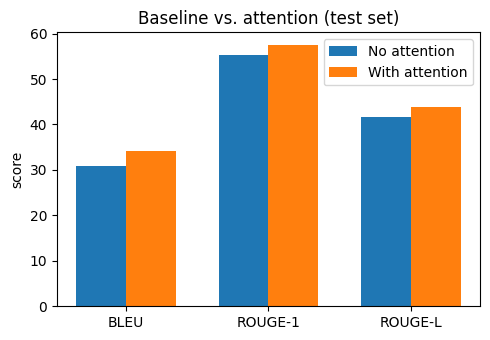

In [32]:
# Comparison table (the one required by the project description)
base, att = results_df.iloc[0], results_df.iloc[1]
comparison = results_df[["model", "params", "train time (min)", "best val loss",
                         "test ppl", "token acc", "BLEU", "ROUGE-1", "ROUGE-L"]].copy()
comparison["token acc"] = (comparison["token acc"] * 100).round(1)   # as a percentage
display(comparison)

# Relative change with attention
for m in ["best val loss", "test ppl", "token acc", "BLEU", "ROUGE-1", "ROUGE-L"]:
    print(f"{m:14s} {base[m]:8.3f} -> {att[m]:8.3f}   ({(att[m] - base[m]) / base[m] * 100:+.1f}%)")

# Bar chart of the generation metrics
metrics = ["BLEU", "ROUGE-1", "ROUGE-L"]
x, w = np.arange(len(metrics)), 0.35
plt.figure(figsize=(5, 3.5))
plt.bar(x - w/2, [base[m] for m in metrics], w, label="No attention")
plt.bar(x + w/2, [att[m] for m in metrics], w, label="With attention")
plt.xticks(x, metrics); plt.ylabel("score"); plt.legend()
plt.title("Baseline vs. attention (test set)")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/comparison.png", dpi=150)
plt.show()

**Analysis.**
- Relative changes with attention: perplexity −2.5%, token accuracy +1.1% (+0.8 points), BLEU +10.9%, ROUGE-1 +4.0%, ROUGE-L +5.4%. For perplexity, lower is better.
- The gain is larger on whole generated replies (BLEU, ROUGE) than on next-token loss. Attention probably keeps the reply closer to the input words.
- The gain is modest because the inputs are very short (median 9 tokens): one 256-dimensional vector already holds most of the message. Attention is expected to matter more for long inputs.
- Cost vs. gain: attention needs 1.5× the parameters and 2.2× the training time for a moderate improvement.
- Caveat: each model was trained once, with one seed, so small differences may partly be noise.

## 12- Best and worst examples

In [33]:
gen_df["intent"] = test_df["intent"].values
gen_df["rougeL_base"] = [scorer.score(r, h)["rougeL"].fmeasure for r, h in zip(gen_df["reference"], gen_df["baseline"])]
gen_df["rougeL_attn"] = [scorer.score(r, h)["rougeL"].fmeasure for r, h in zip(gen_df["reference"], gen_df["attention"])]

def show(df, n=3):
    for _, r in df.head(n).iterrows():
        print(f"INPUT    : {r['input']}")
        print(f"REFERENCE: {r['reference']}")
        print(f"BASELINE : {r['baseline']}   [ROUGE-L {r['rougeL_base']:.2f}]")
        print(f"ATTENTION: {r['attention']}   [ROUGE-L {r['rougeL_attn']:.2f}]")
        print("-" * 80)

print("=== BEST (attention) ===")
show(gen_df.sort_values("rougeL_attn", ascending=False))
print("=== WORST (attention) ===")
show(gen_df.sort_values("rougeL_attn"))

=== BEST (attention) ===
INPUT    : help me checking the current status of purchase <order_number>
REFERENCE: thank you for reaching out! i'm here to assist you in checking the current status of your purchase with the purchase number <order_number>. to provide you with accurate information, could you please provide me with some additional details such as your name and email address associated with the purchase? this will help me locate your purchase and provide you with the most up-to-date status.
BASELINE : thank you for reaching out! i'm here to assist you in checking the current status of your purchase with the order number <order_number>. to provide you with accurate information, could you please provide me with your order number or any other relevant details? this will help me locate your order and provide you with the most accurate information. thank you for your cooperation, and i appreciate your patience as we work together to resolve this matter.   [ROUGE-L 0.68]
ATTENTION: th

**Analysis.**

*Successes.* In the best cases the attention model reproduces the reference's structure and asks for the right information. For "i need assistance changing the address" it asks for the current and the new address (ROUGE-L 0.86), while the baseline says "editing" and drops the current address (0.53). For the order-status request it keeps the key phrases (0.89 vs. 0.68).

*Failures.*
1. **Repetition loop:** for "assistance submitting feedback for ur services", greedy decoding with attention repeats "areas where we excel and" until the length limit (ROUGE-L 0.11). Greedy decoding always picks the most likely token, so once a loop starts it cannot escape.
2. **Generic deflection:** for "are there early termination fees?" and "how long reimbursements take", the references give direct information, but both models ask for account or order details or invent a procedure (ROUGE-L 0.13 to 0.18). The model learns the style of support replies, not company facts.
3. **Language slips**, e.g. the baseline's "the long reimbursements for reimbursements".
4. **Unknown-token artifacts:** the `⁇` symbols in a reference come from rare characters, mostly in numbers like "5-3 business days", mapped to `<UNK>`.

***which inputs are difficult?***

In [37]:
# 1) by intent
by_intent = (
    gen_df.groupby("intent", observed=True)[
        ["rougeL_base", "rougeL_attn"]
    ]
    .mean()
    .round(3)
    .sort_values("rougeL_attn")
)
print(by_intent.head(5))
print(by_intent.tail(5))

# 2) by reference length (quartiles)
gen_df["ref_words"] = gen_df["reference"].str.split().str.len()
print(gen_df.groupby(
    pd.qcut(gen_df["ref_words"], 4), observed=True)[
        ["rougeL_base", "rougeL_attn"]
        ]
      .mean()
      .round(3)
      )

# 3) how often does attention beat the baseline?
print("attention better:", (gen_df["rougeL_attn"] > gen_df["rougeL_base"]).mean())

                         rougeL_base  rougeL_attn
intent                                           
review                         0.346        0.355
edit_account                   0.360        0.358
change_shipping_address        0.358        0.364
complaint                      0.348        0.376
get_refund                     0.353        0.386
                     rougeL_base  rougeL_attn
intent                                       
track_order                0.447        0.504
check_refund_policy        0.502        0.520
delivery_period            0.545        0.546
cancel_order               0.510        0.558
switch_account             0.536        0.558
                rougeL_base  rougeL_attn
ref_words                               
(11.999, 71.0]        0.424        0.429
(71.0, 89.0]          0.400        0.424
(89.0, 123.0]         0.393        0.418
(123.0, 226.0]        0.449        0.485
attention better: 0.5959821428571429


**Analysis.**
- **By intent:** the hardest intents for the attention model are review (ROUGE-L 0.355), edit_account (0.358), change_shipping_address (0.364), complaint (0.376) and get_refund (0.386). The easiest are switch_account and cancel_order (0.558), delivery_period (0.546), check_refund_policy (0.520) and track_order (0.504). A likely reason, to be checked on examples, is that the hard intents are open-ended: the right reply depends on details the model cannot know, so references vary a lot.
- **Where attention helps most:** track_order (+0.057), get_refund (+0.033) and complaint (+0.028). It helps almost nothing for review, edit_account and delivery_period.
- **By length:** the longest responses (123 to 226 words) are not the hardest. They score highest (0.485 attention, 0.449 baseline), while mid-length ones score lowest (0.418 to 0.424 attention). Probably, long replies share more common phrases with the output.
- **Win rate:** attention is better than the baseline on 59.6% of test examples. Its gain is an average effect, not a guarantee.

In [38]:
from collections import Counter

# 1) How often do outputs contain a looping phrase?
def has_loop(text, n=4, k=3):
    w = text.split()
    grams = [tuple(w[i:i+n]) for i in range(len(w) - n + 1)]
    return max(Counter(grams).values(), default=0) >= k

for col in ["baseline", "attention"]:
    print(col, "outputs with a repeated 4-gram (3+ times):", gen_df[col].map(has_loop).mean())

# 2) How much of the training text becomes <UNK>?
sample = train_df["response"].sample(2000, random_state=1)
ids = np.array([i for t in sample for i in sp.encode(t)])
print("UNK rate:", (ids == UNK).mean())
print(sp.encode("1-2 business days", out_type=str))

baseline outputs with a repeated 4-gram (3+ times): 0.008928571428571428
attention outputs with a repeated 4-gram (3+ times): 0.039806547619047616
UNK rate: 0.001442313568748243
['▁1', '-', '2', '▁business', '▁days']


**Analysis.**
- **Repetition:** about 0.9% of baseline outputs contain a 4-word phrase repeated 3 or more times, against about 4.0% for the attention model (roughly 4.5 times more). So attention improves the average scores but loops more often under greedy decoding. These looping outputs score very low, so fixing them (for example with a repetition penalty or a no-repeat n-gram rule) would probably raise attention's scores further. This is a simple heuristic, so the percentages are approximate.
- **Unknown tokens:** only 0.14% of training tokens are `<UNK>`, so subword tokenization handles unknown and misspelled words well. "1-2 business days" tokenizes cleanly.

## 13- Discussion and conclusion

**Does the model learn the task?** Yes. Both models write fluent, relevant support replies, with a test perplexity of about 3, and they keep the placeholders. There is no overfitting.

**Does attention help?** Yes, moderately: better on all metrics (BLEU +3.3, ROUGE-L +2.2) and better on 60% of test examples, at 1.5× the parameters and 2.2× the training time. The gain is small because inputs are very short.

**What fails?** Mostly content, not language: generic replies, invented procedures (the model learns the style of support replies, not company facts), and repetition loops, which are more frequent with attention (about 4% vs. 0.9%). Open-ended intents (review, complaint, edit_account) are the hardest.

**Limitations.**
- The dataset is synthetic and templated (13.5% of test messages also appear in training, with a different reply), so scores are likely higher than on real customer chats.
- Each model was trained once (one seed), so small differences may partly be noise.
- 4.4% of responses are truncated at 256 tokens, and line breaks are removed during cleaning.
- BLEU and ROUGE use a single reference and penalize valid paraphrases.
- Only greedy decoding was tested. 251 of the 314 placeholder tokens are rare.

**Possible improvements.** A bidirectional encoder, repeated runs with different seeds, a Transformer encoder–decoder, a larger vocabulary.

**Conclusion.** A GRU encoder–decoder trained from scratch can generate fluent customer-support replies, and adding attention gives a consistent but moderate gain at a clear computational cost.

## Appendix: recovery after a Colab disconnect
Run the cell below **only if** the Colab session was reset after training. It reloads the data splits, the tokenizer, the best weights and the training histories from Google Drive, so nothing needs to be retrained. Skip it if training ran in this session.

In [12]:
import json, sentencepiece as spm

# data and tokenizer from Drive
train_df = pd.read_csv(f"{SAVE_DIR}/train.csv")
val_df   = pd.read_csv(f"{SAVE_DIR}/val.csv")
test_df  = pd.read_csv(f"{SAVE_DIR}/test.csv")
sp = spm.SentencePieceProcessor(model_file=f"{SAVE_DIR}/bpe.model")
VOCAB_SIZE = sp.get_piece_size()

# models with their best weights
baseline   = build_model(False)
attn_model = build_model(True)
baseline.load_state_dict(torch.load(f"{SAVE_DIR}/baseline_best.pt", map_location=device))
attn_model.load_state_dict(torch.load(f"{SAVE_DIR}/attention_best.pt", map_location=device))

# training histories (losses per epoch, training time)
hist_base = json.load(open(f"{SAVE_DIR}/baseline_history.json"))
hist_attn = json.load(open(f"{SAVE_DIR}/attention_history.json"))